# RNN Humanoid Trajectory Prediction - Complete Instructor Solution

EMEN 7029 / 7104 - PyTorch - PHUMA / Unitree G1

**Task: use 20 historical XY positions to predict the next 10 positions (one second).**
Use the open PHUMA G1 walking subset to implement an Elman RNN and a gated RNN manually, and compare them with a constant-velocity baseline.
This task predicts 2D root trajectories from robot **reference motions**; it does not use real-robot execution logs or perform whole-body control.

Upload this notebook to [Google Colab](https://colab.research.google.com/) and select a Python 3 CPU runtime.
The data and shared code are embedded, so this single notebook is sufficient; no data-service account is required to obtain the subset.
For local use, Python 3.12 and Jupyter are recommended. Execution creates `humanoid_rnn_workspace/` in the current directory.

Run all cells from top to bottom to retrain. Saved outputs come from an actual CPU execution; execution does not depend on those outputs.

The teaching format follows the reference assignment: task description -> TODO implementation -> visual verification -> generalization analysis.

## 0. Environment

Small models are trained on the CPU by default. This cell does not access the network when the required libraries are already installed; it installs missing libraries automatically.
The full experiment trains each model for 100 epochs. Runtime depends on your machine.

In [1]:
import importlib.util
import os
from pathlib import Path
import subprocess
import sys

requirements = {"numpy": "numpy>=1.26,<3", "torch": "torch>=2.2,<3",
                "matplotlib": "matplotlib>=3.8,<4"}
missing = [spec for name, spec in requirements.items()
           if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
ROOT = Path.cwd() / "humanoid_rnn_workspace"
ROOT.mkdir(exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".mplconfig"))
os.environ.setdefault("XDG_CACHE_HOME", str(ROOT / ".cache"))
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import Image, Markdown, display
torch.set_default_dtype(torch.float32)
print("Python:", sys.version.split()[0], "PyTorch:", torch.__version__, "NumPy:", np.__version__)
print("Workspace:", ROOT)

Python: 3.12.13 PyTorch: 2.15.0 NumPy: 2.5.4
Workspace: /private/var/folders/hg/cy46vq7d3wg86rr95t7_h2qh0000gn/T/humanoid-notebook-check-yx5d1c3w/instructor/humanoid_rnn_workspace


## 1. Dataset selection and task scope

Verification date: 2026-10-30. This experiment does not use NGSIM or replace trajectories from the actual data files with artificially generated Bezier curves.

## The two candidate datasets

| Aspect | Kaggle Humanoid Robot Navigation | PHUMA (selected) |
| --- | --- | --- |
| Original link | https://www.kaggle.com/datasets/zara2099/humanoid-robot-navigation-dataset | https://arxiv.org/html/2510.26236v3 |
| Availability | CSV downloaded and inspected: 1,000 rows and 13 columns | Public official Hugging Face release; a fixed revision can be retrieved |
| Contents | Navigation status, terrain, energy consumption, stability, Bezier control points, etc. | Per-frame root position, orientation, joint positions, and frame rate for G1/H1-2 |
| Suitability for continuous position forecasting | Lacks per-frame actual positions, sampling intervals, and reliable episode boundaries needed for this task | `root_trans` and `fps` directly support history/future windows |
| Suitable simple task | Navigation outcome classification or score regression; provenance needs further verification | Short-term 2D root trajectory forecasting for G1 walking motions |
| Publisher's license declaration | CC0 | Hugging Face data card: Apache-2.0; upstream source restrictions still apply |

The actual Kaggle CSV fields are: `time_step, robot_id, terrain_type, obstacle_count, obstacle_distance, bezier_control_points, planned_trajectory_length, mpc_adjustment, gait_stability_index, center_of_mass_offset, energy_consumption, navigation_status, navigation_score`.

The schema verification record and two sample rows are in `data/sources/kaggle_schema_verified.json`. The presence of `time_step` and `robot_id` alone does not establish that rows represent continuous motion at regular sampling intervals. Bezier control points describe a planned path; they cannot be treated as observed positions along an executed trajectory.

## PHUMA sources

- Paper: Lee et al., *PHUMA: Physically Reliable Humanoid Locomotion Dataset*, arXiv:2510.26236v3.
- Official code: https://github.com/DAVIAN-Robotics/PHUMA
- Project page: https://davian-robotics.github.io/PHUMA/
- Official data: https://huggingface.co/datasets/DAVIAN-Robotics/PHUMA
- Pinned revision: `48b0f5982969104ab041461e594a8b8c36db8ba5`.
- Original fields: `root_trans (T,3)`, `root_ori (T,4)`, `dof_pos (T,D)`, and `fps`.

PHUMA processes human motion data using physical constraints and retargets the motions to humanoid robots. The trajectories in these public files are **robot reference motions**, not execution logs measured by sensors on a physical robot. The paper primarily addresses motion imitation and control. This assignment instead defines a supervised trajectory forecasting task; it does not reproduce the paper's main experiments.

## A small, reproducible subset

Select motions under `data/g1/idea400/` whose filenames contain `walking` and match `number_|hand_pockets|arm_swing|clapping|salute|waving|pointing`. These are walking motions accompanied by simple upper-body actions. Other robots, sources, and more complex motion categories are excluded. The selection does not imply a strict label of straight-line, constant-speed walking.

The subset contains 295 segments, 169 source motions grouped by name, and 29,856 original frames at 30 Hz. Taking every third frame produces 10,006 frames at 10 Hz. XYZ positions are retained, while the model uses only horizontal XY coordinates. The approximately 111 KiB NPZ is embedded in both notebooks, avoiding the need for a data account or the complete archive of approximately 3.4 GB. `prepare_phuma.py` can reconstruct the same subset from the pinned official release using HTTP Range requests.

Selection does not depend on prediction error. Each original file's path, SHA-256, CRC, frame rate, and length are recorded in `data/manifest.json`. The hashes of all 295 cached original files were checked, and the NPZ coordinates were verified to exactly match the original `root_trans[::3]`. Classroom NPZ loading uses `allow_pickle=False`; the reconstruction tool permits only the NumPy types needed by the original NPY dictionaries.

Source names are grouped after removing `_clip...` / `_chunk...` suffixes. Splitting occurs before windowing, and separate segments are never concatenated. The default window requires at least 30 frames, leaving 157 usable source motions: 109 for training, 23 for validation, and 25 for testing. Their window counts are 794, 172, and 191, respectively. The remaining 12 source motions do not meet the length requirement.

## Limits on interpretation

1. Splitting by source name prevents chunks of the same source motion from appearing in different sets. Reliable actor IDs are unavailable, so actor-independent evaluation cannot be claimed, and correlations between differently named motions cannot be ruled out.
2. Neighboring windows overlap. The report includes both averages over windows and averages giving equal weight to each source motion. All windows must not be treated as independent samples when calculating confidence intervals.
3. No additional smoothing or interpolation is applied here. PHUMA's upstream pipeline already includes motion processing and physical optimization. The results measure the predictability of processed reference trajectories, not noisy online sensor measurements from a physical robot.
4. XY forecasts omit whole-body joints, orientation, obstacles, contacts, and control inputs. They cannot directly serve as a robot controller or guarantee dynamic feasibility. The deterministic RNN also does not model multiple possible future intentions.
5. The current result uses one fixed split and seed for classroom purposes. Generalization across scenes, sources, robots, seeds, and longer horizons requires separate evaluation.

## Licensing and citation

The package retains `data/sources/PHUMA_DATA_CARD.md`, `PHUMA_LICENSE.txt`, and `PHUMA_REPOSITORY_README.md`. The official data card explicitly states that the public release excludes restricted motions derived from LAFAN1 and LocoMuJoCo. This subset uses only the IDEA400 portion of the public archive. Apache-2.0 is the publisher's declaration for that data repository; it does not remove rights associated with the original human motion sources. The paper's CC BY 4.0 license is not the dataset license. Review the upstream Motion-X / IDEA400 terms before further public redistribution or commercial use.

```bibtex
@article{lee2025phuma,
  title={PHUMA: Physically Reliable Humanoid Locomotion Dataset},
  author={Lee, Kyungmin and Kim, Sibeen and Lee, Youngdo and Park, Minho
          and Kim, Hyunseung and Hwang, Dongyoon and Kim, Donghu
          and Lee, Hojoon and Choo, Jaegul},
  journal={arXiv preprint arXiv:2510.26236},
  year={2025}
}
```


The collapsed cell below only unpacks public data, provenance records, and license text. It contains no model answers and requires no editing.

In [2]:
# @title Restore the bundled public motion subset and provenance
import base64
import hashlib
import io
import json
import zipfile

DATA_B64 = "..."
archive_bytes = base64.b64decode(DATA_B64)
assert hashlib.sha256(archive_bytes).hexdigest() == "fa203945c2abbe05f57e5cae7c096bcfb2a1a07e97586bc455445f7a5d6e160a"
with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
    for name in archive.namelist():
        destination = (ROOT / name).resolve()
        if not destination.is_relative_to(ROOT.resolve()):
            raise ValueError("Unsafe archive path")
        content = archive.read(name)
        if destination.exists() and destination.read_bytes() != content:
            raise FileExistsError(f"Existing file differs: {destination}; use a new workspace")
        destination.parent.mkdir(parents=True, exist_ok=True)
        destination.write_bytes(content)
DATA = ROOT / "data" / "phuma_g1_walking.npz"
manifest = json.loads((DATA.parent / "manifest.json").read_text())
assert hashlib.sha256(DATA.read_bytes()).hexdigest() == manifest["sha256_npz"]
print("Data:", manifest["dataset"], manifest["robot"])
print("Sequences / source groups / frames:", manifest["num_sequences"],
      manifest["num_source_groups"], manifest["frames_10hz"])
print("Revision:", manifest["revision"])
del DATA_B64, archive_bytes

Data: PHUMA Unitree G1
Sequences / source groups / frames: 295 169 10006
Revision: 48b0f5982969104ab041461e594a8b8c36db8ba5


## 2. Model design and grading

Goal: manually implement RNNs on the PHUMA Unitree G1 walking subset to predict the next one second of root trajectory from historical planar positions. After completing the 13 TODO blocks, the student notebook should provide the same functionality as the complete instructor version. Data loading, grouped splits, normalization, validation-based model selection, and plotting are provided.

This assignment uses the interfaces `f(h,x)`, `g(h)`, `initial_recurrent_state(batch_size)`, and `scan`. To learn recurrence and gradient propagation, do not call `nn.RNN/GRU/LSTM` or their Cell variants, and do not override the model's `forward` method. You may use `nn.Linear`, tensor operations, and optimizers.

## 1. Data and time conventions

The data come from the [official public PHUMA release](https://huggingface.co/datasets/DAVIAN-Robotics/PHUMA). They are retargeted robot reference motions, not execution logs from a physical robot. The subset includes simple G1 walking motions with accompanying upper-body actions. Horizontal XY coordinates from `root_trans` are in meters. Sampling every third frame reduces the original 30 Hz rate to 10 Hz. Do not modify the fixed dataset or select test examples based on prediction error.

- `B`: batch size; `O=20`: number of observed points; `H=10`: number of future points.
- Historical times are `-1.9,-1.8,...,0` seconds, spanning 1.9 seconds and commonly described as approximately two seconds of history.
- Future times are `0.1,0.2,...,1.0` seconds; `dt=0.1`.
- Input dimension `D_x=4`, hidden dimension `D_h=32`, and output dimension `D_y=2H=20`.
- Clips/chunks from the same source motion stay in the same split. Split source motions before windowing; windows must not cross segment boundaries.
- Estimate means and standard deviations from the training set only. Inputs, velocities, baselines, and inference must not use future ground truth.

## 2. Tasks and grading

| Task | Points | TODO identifiers |
| --- | ---: | --- |
| Historical position and velocity features | 10 | `features` |
| Elman RNN parameters, update, output, and initial state | 20 | `elman_init / elman_f / elman_g / elman_h0` |
| Temporal scan that preserves gradients | 15 | `scan` |
| Multi-step residual forecasting | 10 | `predict` |
| One-epoch training loop | 15 | `train` |
| ADE / FDE in meters | 10 | `metrics` |
| Custom gated RNN | 15 | `custom_init / custom_f / custom_g / custom_h0` |
| Experimental results and interpretation | 5 | Report |

## 3. Shared experiment code (provided)

Pipeline: split by source motion -> create windows within each segment -> normalize using training statistics -> fit a historical constant-velocity baseline -> predict RNN residuals -> select checkpoints by validation ADE -> evaluate on the test set.

These functions provide the experiment infrastructure. Complete the model and training functions below.
The shared experiment runner calls your implementation of `train_one_epoch`; it does not bypass it.

In [3]:
"""Provided infrastructure shared by the instructor and student versions."""

import argparse
import hashlib
import json
import os
from pathlib import Path
import random
import time

import numpy as np
import torch
from torch.utils.data import DataLoader, TensorDataset

ROOT = Path.cwd() / "humanoid_rnn_workspace"
DATA = ROOT / "data" / "phuma_g1_walking.npz"
DT = 0.1
OUTPUT_SCALE = 1.0
DATA_URL = "https://huggingface.co/datasets/DAVIAN-Robotics/PHUMA"


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True)


def read_tracks(path):
    """Group separate motion chunks by their original source recording."""
    if not path.exists():
        raise FileNotFoundError("Use bundled data or run python prepare_phuma.py first.")
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    manifest_path = path.with_name("manifest.json")
    manifest = json.loads(manifest_path.read_text())
    if digest != manifest["sha256_npz"]:
        raise ValueError("Dataset checksum differs from manifest.json.")
    with np.load(path, allow_pickle=False) as data:
        xyz, offsets, groups, names = (data[k] for k in ("root_xyz", "offsets", "groups", "names"))
        if float(data["fps"]) != 1 / DT:
            raise ValueError("Expected 10 Hz positions.")
        if (xyz.ndim != 2 or xyz.shape[1] != 3 or not np.isfinite(xyz).all()
                or offsets.shape != (len(groups) + 1,) or len(names) != len(groups)
                or offsets[0] != 0 or offsets[-1] != len(xyz)
                or not np.all(np.diff(offsets) > 0)):
            raise ValueError("Malformed motion arrays.")
        tracks = {}
        for i, group in enumerate(groups):
            # Never concatenate chunks: there may be temporal gaps between them.
            tracks.setdefault(str(group), []).append(xyz[offsets[i]:offsets[i+1], :2].copy())
    return tracks, {"sha256_npz": digest, "sequences": len(groups), "source_groups": len(tracks),
                    "revision": manifest["revision"], "raw_frames": sum(m["frames_raw"] for m in manifest["sequences"])}


def split_tracks(tracks, seed, minimum_length):
    ids = np.array([i for i in sorted(tracks)
                    if any(len(segment) >= minimum_length for segment in tracks[i])])
    if len(ids) < 15:
        raise ValueError("At least 15 sufficiently long source recordings are required.")
    np.random.default_rng(seed).shuffle(ids)
    n_train, n_val = int(0.7 * len(ids)), int(0.15 * len(ids))
    splits = {"train": ids[:n_train], "val": ids[n_train:n_train + n_val], "test": ids[n_train + n_val:]}
    assert len(set(np.concatenate(list(splits.values())))) == len(ids)
    return {name: sorted(map(str, values)) for name, values in splits.items()}


def make_windows(tracks, ids, obs_len, pred_len, stride):
    observed, future, source_ids = [], [], []
    for source in ids:
        for segment in tracks[source]:
            for start in range(0, len(segment) - obs_len - pred_len + 1, stride):
                observed.append(segment[start:start + obs_len])
                future.append(segment[start + obs_len:start + obs_len + pred_len])
                source_ids.append(source)
    if not observed:
        raise ValueError("Split contains no complete windows.")
    return torch.from_numpy(np.stack(observed)), torch.from_numpy(np.stack(future)), source_ids


def constant_velocity(observed, pred_len, dt=DT):
    """OLS velocity over the last 0.5 seconds; anchor prediction at last observation."""
    count = min(observed.shape[1], round(0.5 / dt) + 1)
    times = torch.arange(count, device=observed.device, dtype=observed.dtype) * dt
    times = times - times.mean()
    velocity = (observed[:, -count:] * times[None, :, None]).sum(1) / times.square().sum()
    horizon = torch.arange(1, pred_len + 1, device=observed.device,
                           dtype=observed.dtype) * dt
    return velocity[:, None] * horizon[None, :, None]


@torch.no_grad()
def evaluate(model, loader, predict, errors, device):
    model.eval()
    predictions, ade, fde = [], [], []
    for xs, baseline, target in loader:
        prediction = predict(model, xs.to(device), baseline.to(device), OUTPUT_SCALE).cpu()
        a, f = errors(prediction, target)
        predictions.append(prediction)
        ade.append(a)
        fde.append(f)
    return {"ADE_m": torch.cat(ade).mean().item(), "FDE_m": torch.cat(fde).mean().item()}, torch.cat(predictions)


def plot_results(out, histories, observed, target, predictions, baseline, source_ids):
    os.environ.setdefault("MPLCONFIGDIR", str(out / ".mplconfig"))
    os.environ.setdefault("XDG_CACHE_HOME", str(out / ".cache"))
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(7, 4))
    for name, history in histories.items():
        ax.plot(range(1, len(history) + 1), [x["val_ADE_m"] for x in history], label=name)
    ax.set(xlabel="Epoch", ylabel="Validation ADE (m)")
    ax.legend()
    fig.tight_layout()
    fig.savefig(out / "learning_curves.png", dpi=160)
    plt.close(fig)
    # Fixed indices chosen without looking at prediction errors.
    indices = np.linspace(0, len(target) - 1, 6, dtype=int)
    fig, axes = plt.subplots(2, 3, figsize=(13, 8))
    for ax, index in zip(axes.flat, indices):
        obs = observed[index] - observed[index, -1:]
        ax.plot(obs[:, 0], obs[:, 1], "o-", ms=2, color="0.5", label="History")
        for label, values, style in [("Truth", target, "k-"), ("CV", baseline, "--")]:
            points = torch.cat((torch.zeros(1, 2), values[index]))
            ax.plot(points[:, 0], points[:, 1], style, label=label)
        for name, values in predictions.items():
            points = torch.cat((torch.zeros(1, 2), values[index]))
            ax.plot(points[:, 0], points[:, 1], label=name)
        ax.set(title=f"Test window {index}", xlabel="Root x displacement (m)", ylabel="Root y displacement (m)")
        ax.set_aspect("equal", adjustable="datalim")
        ax.grid(alpha=0.2)
    axes.flat[0].legend(fontsize=8)
    fig.suptitle(f"PHUMA G1 held-out recordings: {target.shape[1] * DT:g}-second root forecast")
    fig.tight_layout()
    fig.savefig(out / "trajectories.png", dpi=160)
    plt.close(fig)
    fig, ax = plt.subplots(figsize=(7, 4))
    for name, forecast in {"constant velocity": baseline, **predictions}.items():
        error = torch.linalg.vector_norm(forecast - target, dim=-1).mean(0)
        ax.plot(np.arange(1, len(error) + 1) * DT, error, label=name)
    ax.set(xlabel="Time after last observation (s)", ylabel="Mean displacement error (m)")
    ax.legend()
    ax.grid(alpha=0.2)
    fig.tight_layout()
    fig.savefig(out / "error_by_horizon.png", dpi=160)
    plt.close(fig)


def run_experiment(model_classes, feature_fn, predict, train_one_epoch, errors, argv=None):
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--data", type=Path, default=DATA)
    parser.add_argument("--output", type=Path, default=ROOT / "outputs" / "my_run")
    parser.add_argument("--epochs", type=int, default=100)
    parser.add_argument("--batch-size", type=int, default=128)
    parser.add_argument("--hidden", type=int, default=32)
    parser.add_argument("--lr", type=float, default=0.001)
    parser.add_argument("--seed", type=int, default=42)
    parser.add_argument("--obs-len", type=int, default=20)
    parser.add_argument("--pred-len", type=int, default=10)
    parser.add_argument("--stride", type=int, default=2)
    parser.add_argument("--model", choices=["both", "elman", "gated"], default="both")
    parser.add_argument("--device", choices=["cpu", "cuda"], default="cpu")
    parser.add_argument("--threads", type=int, default=2)
    args = parser.parse_args(argv)
    if min(args.epochs, args.batch_size, args.hidden, args.pred_len, args.stride, args.threads) < 1 or args.obs_len < 2 or args.lr <= 0:
        parser.error("Lengths/counts/lr must be positive, and obs-len must be >= 2.")
    if (args.output / "metrics.json").exists():
        parser.error("Output already contains an experiment; choose a new --output directory.")
    args.output.mkdir(parents=True, exist_ok=True)
    if args.device == "cuda":
        os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
    torch.set_num_threads(args.threads)
    seed_everything(args.seed)
    tracks, provenance = read_tracks(args.data)
    splits = split_tracks(tracks, args.seed, args.obs_len + args.pred_len)
    windows = {s: make_windows(tracks, ids, args.obs_len, args.pred_len, args.stride)
               for s, ids in splits.items()}
    features = {s: feature_fn(w[0], DT) for s, w in windows.items()}
    mean = features["train"].mean(dim=(0, 1), keepdim=True)
    std = features["train"].std(dim=(0, 1), keepdim=True).clamp_min(1e-3)
    datasets = {}
    for s, (observed, future, _) in windows.items():
        datasets[s] = TensorDataset((features[s] - mean) / std,
                                    constant_velocity(observed, args.pred_len),
                                    future - observed[:, -1:])
    counts = {s: {"source_recordings": len(splits[s]), "windows": len(datasets[s])} for s in splits}
    print(json.dumps(counts, indent=2), flush=True)
    config = {k: str(v) if isinstance(v, Path) else v for k, v in vars(args).items()}
    report = {"config": config, "dt_seconds": DT, "counts": counts,
              "data": {**provenance, "url": DATA_URL}, "split_source_ids": splits,
              "versions": {"torch": str(torch.__version__), "numpy": np.__version__},
              "test": {}, "models": {}}
    (args.output / "splits.json").write_text(json.dumps(splits, indent=2))
    val_loader = DataLoader(datasets["val"], batch_size=args.batch_size)
    histories, models = {}, {}
    val_cv = errors(datasets["val"].tensors[1], datasets["val"].tensors[2])
    report["validation_constant_velocity"] = {"ADE_m": val_cv[0].mean().item(), "FDE_m": val_cv[1].mean().item()}
    print("Validation CV:", report["validation_constant_velocity"], flush=True)
    for name, model_class in model_classes.items():
        if args.model not in ("both", name):
            continue
        seed_everything(args.seed)
        loader = DataLoader(datasets["train"], batch_size=args.batch_size, shuffle=True,
                            generator=torch.Generator().manual_seed(args.seed))
        model = model_class(4, args.hidden, args.pred_len * 2).to(args.device)
        optimizer = torch.optim.AdamW(model.parameters(), lr=args.lr, weight_decay=1e-4)
        best, history, started = float("inf"), [], time.perf_counter()
        for epoch in range(1, args.epochs + 1):
            loss = train_one_epoch(model, loader, optimizer, args.device, OUTPUT_SCALE)
            metric, _ = evaluate(model, val_loader, predict, errors, args.device)
            if not np.isfinite(loss) or not np.isfinite(metric["ADE_m"]):
                raise RuntimeError("Non-finite training/validation metric.")
            history.append({"epoch": epoch, "train_normalized_MSE": loss,
                            "val_ADE_m": metric["ADE_m"], "val_FDE_m": metric["FDE_m"]})
            if metric["ADE_m"] < best:
                best = metric["ADE_m"]
                checkpoint = {"model": name, "state_dict": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                              "mean": mean, "std": std, "config": config, "dt": DT,
                              "output_scale": OUTPUT_SCALE, "epoch": epoch,
                              "val_ADE_m": best, "data_sha256": provenance["sha256_npz"]}
                torch.save(checkpoint, args.output / f"{name}_best.pt")
            if epoch == 1 or epoch % 5 == 0 or epoch == args.epochs:
                print(f"{name:5} {epoch:3}/{args.epochs}: loss={loss:.5f}, "
                      f"val ADE={metric['ADE_m']:.3f} m, FDE={metric['FDE_m']:.3f} m", flush=True)
        model.load_state_dict(checkpoint["state_dict"])
        histories[name], models[name] = history, model
        report["models"][name] = {"best_epoch": checkpoint["epoch"], "val_ADE_m": best,
                                  "training_seconds": time.perf_counter() - started}
    # Test targets are used for final reporting only, after all model selection.
    test_loader = DataLoader(datasets["test"], batch_size=args.batch_size)
    _, baseline, target = datasets["test"].tensors
    for name, forecast in (("constant_velocity", baseline), ("last_position", torch.zeros_like(target))):
        ade, fde = errors(forecast, target)
        report["test"][name] = {"ADE_m": ade.mean().item(), "FDE_m": fde.mean().item()}
    predictions = {}
    for name, model in models.items():
        report["test"][name], predictions[name] = evaluate(model, test_loader, predict, errors, args.device)
    # Also report equally weighted source means; overlapping windows are correlated.
    report["test_macro_source"] = {}
    source_array = np.array(windows["test"][2])
    for name, forecast in {"constant_velocity": baseline, "last_position": torch.zeros_like(target), **predictions}.items():
        a, f = errors(forecast, target)
        report["test_macro_source"][name] = {
            "ADE_m": float(np.mean([a[source_array == group].mean().item() for group in splits["test"]])),
            "FDE_m": float(np.mean([f[source_array == group].mean().item() for group in splits["test"]])),
        }
    report["history"] = histories
    (args.output / "metrics.json").write_text(json.dumps(report, indent=2))
    np.savez_compressed(args.output / "test_predictions.npz", observed=windows["test"][0].numpy(),
                        target_relative=target.numpy(), baseline_relative=baseline.numpy(),
                        source_ids=np.array(windows["test"][2]),
                        **{k + "_relative": v.numpy() for k, v in predictions.items()})
    plot_results(args.output, histories, windows["test"][0], target, predictions, baseline, windows["test"][2])
    print("Final held-out test metrics (meters):", flush=True)
    print(json.dumps(report["test"], indent=2), flush=True)
    print(f"Artifacts: {args.output.resolve()}", flush=True)

train source recordings: 109 windows: 794 history: (794, 20, 2) future: (794, 10, 2)
val source recordings: 23 windows: 172 history: (172, 20, 2) future: (172, 10, 2)
test source recordings: 25 windows: 191 history: (191, 20, 2) future: (191, 10, 2)


Matplotlib is building the font cache; this may take a moment.


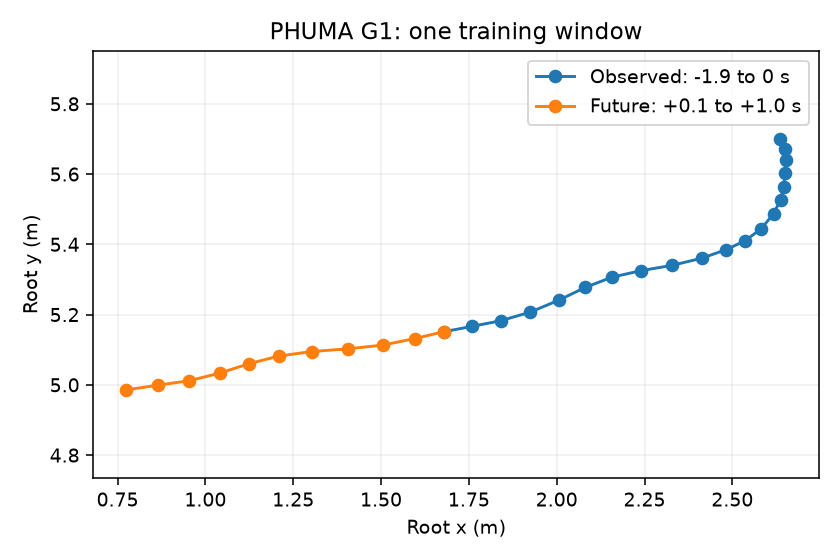

In [4]:
tracks, provenance = read_tracks(DATA)
splits = split_tracks(tracks, seed=42, minimum_length=30)
for name, ids in splits.items():
    observed, future, _ = make_windows(tracks, ids, 20, 10, 2)
    print(name, "source recordings:", len(ids), "windows:", len(observed),
          "history:", tuple(observed.shape), "future:", tuple(future.shape))
assert not (set(splits["train"]) & set(splits["test"]))
assert not (set(splits["val"]) & set(splits["test"]))
assert not (set(splits["train"]) & set(splits["val"]))

# Only a training trajectory is used for this preliminary data visualization.
import matplotlib.pyplot as plt
observed, future, _ = make_windows(tracks, splits["train"], 20, 10, 2)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(observed[0, :, 0], observed[0, :, 1], "o-", label="Observed: -1.9 to 0 s")
connected = torch.cat((observed[0, -1:], future[0]))
ax.plot(connected[:, 0], connected[:, 1], "o-", label="Future: +0.1 to +1.0 s")
ax.set(xlabel="Root x (m)", ylabel="Root y (m)", title="PHUMA G1: one training window")
ax.axis("equal")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
example_path = ROOT / "training_example.png"
fig.savefig(example_path, dpi=140)
plt.close(fig)
display(Image(filename=str(example_path)))

## A. Historical features, 10 points

`make_features(observed,dt)` takes input of shape `(B,O,2)` and returns `(B,O,4)`. The first two channels contain each historical position minus the last observed position. The last two channels contain differences between consecutive historical positions divided by `dt`. Copy the second velocity entry into the first entry. The full history is available when forecasting begins, so this copy does not use information from the prediction interval.

Preserve the time dimension when selecting the last observed position to allow broadcasting. Do not normalize in this function; the shared code applies normalization using training-set statistics only.

In [5]:
def make_features(observed, dt):
    """observed: (B,O,2) meters -> features: (B,O,4), using history only."""
    # BEGIN ANSWER features
    relative = observed - observed[:, -1:, :]
    velocity = torch.zeros_like(observed)
    velocity[:, 1:] = (observed[:, 1:] - observed[:, :-1]) / dt
    velocity[:, 0] = velocity[:, 1]
    return torch.cat((relative, velocity), dim=-1)

## B. Elman RNN, 20 points

Implement `h_t = tanh(W_x x_t + b_x + W_h h_(t-1))` and `g(h)=W_o h+b_o`.

Use `Linear(d_x,d_h)` for the input mapping, `Linear(d_h,d_h,bias=False)` for the recurrent mapping, and `Linear(d_h,d_y)` for the output mapping. Store `self.d_h`, initialize the recurrent weights orthogonally, and initialize both output weights and output bias to zero. This makes the initial forecast equal to the constant-velocity baseline.

`f` returns `(B,D_h)`, and `g` returns `(B,2H)`. The initial hidden state is a zero tensor of shape `(B,D_h)` whose device and dtype match the model parameters.

In [6]:
class ElmanRNN(nn.Module):
    def __init__(self, d_x, d_h, d_y):
        super().__init__()
        # BEGIN ANSWER elman_init
        self.d_h = d_h
        self.input = nn.Linear(d_x, d_h)
        self.recurrent = nn.Linear(d_h, d_h, bias=False)
        self.output = nn.Linear(d_h, d_y)
        nn.init.orthogonal_(self.recurrent.weight)
        # Start from the same constant-velocity baseline for both models.
        nn.init.zeros_(self.output.weight)
        nn.init.zeros_(self.output.bias)
        # END ANSWER elman_init

    def f(self, h, x):
        """h: (B,d_h), x: (B,d_x) -> next hidden state: (B,d_h)."""
        # BEGIN ANSWER elman_f
        return torch.tanh(self.input(x) + self.recurrent(h))
        # END ANSWER elman_f

    def g(self, h):
        """Map final hidden state to all future residual coordinates."""
        # BEGIN ANSWER elman_g
        return self.output(h)
        # END ANSWER elman_g

    def initial_recurrent_state(self, batch_size):
        # BEGIN ANSWER elman_h0
        return self.input.weight.new_zeros((batch_size, self.d_h))

## C. scan, 15 points

The input `xs` has shape `(B,O,D_x)`. Iterate over time dimension 1, calling `f` to update the hidden state at each step, and return `(B,O,D_h)`. A Python loop over time is allowed; process the entire batch together at each step. Do not call `detach()`, convert to NumPy, or reconstruct tensors in ways that break the computation graph. The final hidden state must retain gradients to earlier inputs.

In [7]:
def scan(f, h, xs):
    """Scan time, retaining autograd: (B,O,d_x) -> (B,O,d_h)."""
    # BEGIN ANSWER scan
    states = []
    for x in xs.unbind(dim=1):
        h = f(h, x)
        states.append(h)
    return torch.stack(states, dim=1)

## D. Multi-step forecasting, 10 points

The provided helper fits velocity `v_hat` by least squares over the last six historical positions, which span 0.5 seconds. It produces the constant-velocity forecast relative to the last observation: `baseline[k] = v_hat * (k+1) * dt`.

In `predict(rnn,xs,baseline,output_scale)`, initialize the hidden state, call `scan`, take the last hidden state, apply `g`, and reshape the output to `(B,H,2)`. The forecast is:

`prediction = baseline + output_scale * residual`

`output_scale=1.0` represents a fixed one-meter scale, not a parameter estimated from the test set. Return displacement relative to the last observed point, in meters. To obtain absolute positions, add the last observed position. Predict all future steps in one pass, without teacher forcing or feeding future ground-truth positions back into the model.

In [8]:
def predict(rnn, xs, baseline, output_scale):
    """Normalized history + CV forecast -> future relative positions in meters.

    xs: (B,O,4); baseline: (B,H,2); output_scale: a fixed 1-meter scale.
    No future ground-truth values are available to this function.
    """
    # BEGIN ANSWER predict
    h0 = rnn.initial_recurrent_state(xs.shape[0])
    hs = scan(rnn.f, h0, xs)
    residual = rnn.g(hs[:, -1]).reshape_as(baseline)
    return baseline + output_scale * residual

## E. One training epoch, 15 points

For each `(xs,baseline,target)` batch in `train_one_epoch`, enable training mode and move the tensors to the specified device. Clear gradients, predict, compute `mean(((prediction-target)/output_scale)^2)`, backpropagate, clip the gradient norm to 1.0, and update the optimizer.

Return the epoch's mean loss weighted by the number of samples, as a Python float. The final batch may be smaller, so do not average batch losses with equal weights. The shared experiment code uses AdamW and saves the best model according to validation ADE at each epoch. The test set is used for final reporting.

In [9]:
def train_one_epoch(rnn, loader, optimizer, device, output_scale):
    """One epoch; return sample-weighted normalized coordinate MSE."""
    # BEGIN ANSWER train
    rnn.train()
    total_loss, count = 0.0, 0
    for xs, baseline, target in loader:
        xs, baseline, target = (a.to(device) for a in (xs, baseline, target))
        optimizer.zero_grad(set_to_none=True)
        prediction = predict(rnn, xs, baseline, output_scale)
        loss = ((prediction - target) / output_scale).square().mean()
        loss.backward()
        nn.utils.clip_grad_norm_(rnn.parameters(), max_norm=1.0)
        optimizer.step()
        total_loss += loss.item() * xs.shape[0]
        count += xs.shape[0]
    return total_loss / count

## F. ADE / FDE, 10 points

First calculate `distance[b,k] = sqrt((pred_x-target_x)^2+(pred_y-target_y)^2)`. Then return `ADE[b]=mean_k(distance[b,k])` and `FDE[b]=distance[b,H-1]`. Both tensors have shape `(B,)` and units of meters. Coordinate RMSE is not a substitute for ADE.

In [10]:
def displacement_errors(prediction, target):
    """Return per-window ADE, FDE: two tensors of shape (B,), in meters."""
    # BEGIN ANSWER metrics
    distance = torch.linalg.vector_norm(prediction - target, dim=-1)
    return distance.mean(dim=-1), distance[:, -1]

## G. Custom gated RNN, 15 points

Keep the same interfaces. You may implement the following GRU-style recurrence manually, where `*` denotes elementwise multiplication:

```text
r = sigmoid(W_xr x + b_r + W_hr h)
z = sigmoid(W_xz x + b_z + W_hz h)
n = tanh(W_xn x + b_n + r * (W_hn h))
h_new = z * h + (1-z) * n
```

Each input and recurrent mapping produces `3D_h` values, split into three groups along the last dimension. The recurrent mapping has no bias. Initialize each of the three recurrent weight blocks orthogonally and initialize the output head to zero. Other recurrent architectures are allowed if you explain their equations and respect the shared interfaces. Keep data splits, input information, and training budgets fixed when comparing with Elman. A gated model is not required to outperform Elman.

In [11]:
class MyRNN(nn.Module):
    """A manually implemented gated RNN (GRU equations)."""

    def __init__(self, d_x, d_h, d_y):
        super().__init__()
        # BEGIN ANSWER custom_init
        self.d_h = d_h
        self.input = nn.Linear(d_x, 3 * d_h)
        self.recurrent = nn.Linear(d_h, 3 * d_h, bias=False)
        self.output = nn.Linear(d_h, d_y)
        for weight in self.recurrent.weight.chunk(3, dim=0):
            nn.init.orthogonal_(weight)
        nn.init.zeros_(self.output.weight)
        nn.init.zeros_(self.output.bias)
        # END ANSWER custom_init

    def f(self, h, x):
        # BEGIN ANSWER custom_f
        x_r, x_z, x_n = self.input(x).chunk(3, dim=-1)
        h_r, h_z, h_n = self.recurrent(h).chunk(3, dim=-1)
        reset = torch.sigmoid(x_r + h_r)
        update = torch.sigmoid(x_z + h_z)
        candidate = torch.tanh(x_n + reset * h_n)
        return update * h + (1.0 - update) * candidate
        # END ANSWER custom_f

    def g(self, h):
        # BEGIN ANSWER custom_g
        return self.output(h)
        # END ANSWER custom_g

    def initial_recurrent_state(self, batch_size):
        # BEGIN ANSWER custom_h0
        return self.input.weight.new_zeros((batch_size, self.d_h))

## 4. Implementation checks

After completing A-F, set `MODELS="elman"`. After completing G, set `MODELS="both"`.
The public checks cover physical units, tensor shapes, gradients across time, batch independence, whether training reduces loss, and split isolation.
The small artificial tensors used here only check function correctness. Subsequent training and evaluation use PHUMA data.

In [12]:
MODELS = "both"  # "elman", "gated", or "both"
EPOCHS = 100
DEVICE = "cpu"  # Set "cuda" only with a GPU runtime.

In [13]:
def check(module, model_name):
    torch.manual_seed(9)
    torch.set_num_threads(2)
    times = torch.arange(15) * DT
    history = torch.stack((2 * times, 4 * times), dim=-1)[None].repeat(3, 1, 1)
    features = module.make_features(history, DT)
    assert features.shape == (3, 15, 4)
    assert torch.isfinite(features).all()
    torch.testing.assert_close(module.make_features(history + 20, DT), features, atol=3e-5, rtol=1e-5)
    torch.testing.assert_close(features[:, -1, :2], torch.zeros(3, 2))
    torch.testing.assert_close(features[0, :, 2:], torch.tensor([2.0, 4.0]).expand(15, 2))
    baseline = constant_velocity(history, 15)
    future_times = torch.arange(1, 16) * DT
    exact = torch.stack((2 * future_times, 4 * future_times), dim=-1)
    torch.testing.assert_close(baseline, exact[None].expand(3, 15, 2))
    target = torch.zeros(3, 15, 2)
    shifted = target + torch.tensor([3.0, 4.0])
    ade, fde = module.displacement_errors(shifted, target)
    torch.testing.assert_close(ade, torch.full((3,), 5.0))
    torch.testing.assert_close(fde, torch.full((3,), 5.0))
    shifted.zero_()
    shifted[:, -1, 0] = 15
    ade, fde = module.displacement_errors(shifted, target)
    torch.testing.assert_close(ade, torch.ones(3))
    torch.testing.assert_close(fde, torch.full((3,), 15.0))
    cls = module.ElmanRNN if model_name == "elman" else module.MyRNN
    model = cls(4, 12, 30)
    assert "forward" not in cls.__dict__, "Use f, g, scan as in the assignment."
    forbidden = (nn.RNN, nn.RNNCell, nn.GRU, nn.GRUCell, nn.LSTM, nn.LSTMCell)
    assert not any(isinstance(layer, forbidden) for layer in model.modules())
    xs = torch.randn(3, 15, 4, requires_grad=True)
    hs = module.scan(model.f, model.initial_recurrent_state(3), xs)
    assert hs.shape == (3, 15, 12)
    gradient = torch.autograd.grad(hs[:, -1].square().sum(), xs)[0]
    assert gradient[:, 0].abs().sum() > 0, "scan detached the recurrent history."
    pred = module.predict(model, xs, baseline, 1.0)
    assert pred.shape == (3, 15, 2) and torch.isfinite(pred).all()
    torch.testing.assert_close(pred, baseline)
    double_model = cls(4, 12, 20).double()
    assert double_model.initial_recurrent_state(2).dtype == torch.float64
    default_pred = module.predict(double_model, torch.randn(2, 20, 4, dtype=torch.float64),
                                  torch.zeros(2, 10, 2, dtype=torch.float64), 1.0)
    assert default_pred.shape == (2, 10, 2)
    for i in range(3):
        torch.testing.assert_close(pred[i:i + 1], module.predict(model, xs[i:i + 1], baseline[i:i + 1], 1.0))
    # A tiny learnable residual task catches a missing backward/optimizer step.
    learning_target = baseline + 0.5
    loader = DataLoader(TensorDataset(xs.detach(), baseline, learning_target), batch_size=3)
    before = ((pred.detach() - learning_target) ** 2).mean().item()
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.01)
    for _ in range(25):
        loss = module.train_one_epoch(model, loader, optimizer, "cpu", 1.0)
        assert isinstance(loss, (float, int)) and loss >= 0
    after = ((module.predict(model, xs, baseline, 1.0) - learning_target) ** 2).mean().item()
    assert after < before * 0.3, f"Training did not fit the tiny task: {before} -> {after}"
    # Unequal batch sizes must still produce a sample-weighted epoch loss.
    unequal_target = baseline + torch.tensor([0.1, 0.2, 2.0])[:, None, None]
    unequal_loader = DataLoader(TensorDataset(xs.detach(), baseline, unequal_target), batch_size=2)
    expected = ((module.predict(model, xs, baseline, 1.0) - unequal_target) ** 2).mean().item()
    actual = module.train_one_epoch(model, unequal_loader, torch.optim.SGD(model.parameters(), lr=0), "cpu", 1.0)
    assert abs(expected - actual) < 1e-5, "Epoch loss must weight by batch size."
    tracks, _ = read_tracks(DATA)
    splits = split_tracks(tracks, 42, 30)
    assert len(set(sum(splits.values(), []))) == sum(map(len, splits.values()))
    for ids in splits.values():
        observed, future, groups = make_windows(tracks, ids, 20, 10, 2)
        assert observed.shape[1:] == (20, 2) and future.shape[1:] == (10, 2)
        assert set(groups) == set(ids)
    # Short chunks cannot be joined to manufacture an otherwise invalid window.
    try:
        make_windows({"source": [torch.zeros(19, 2).numpy(), torch.zeros(19, 2).numpy()]}, ["source"], 20, 10, 2)
        raise AssertionError("Windows crossed a chunk boundary.")
    except ValueError:
        pass
    print(f"PASS: {model_name}: shapes, units, metrics, history gradients, independent batches, training, splits")

from types import SimpleNamespace
implementation = SimpleNamespace(make_features=make_features, ElmanRNN=ElmanRNN,
    MyRNN=MyRNN, scan=scan, predict=predict, train_one_epoch=train_one_epoch,
    displacement_errors=displacement_errors)
assert MODELS in ("both", "elman", "gated")
for model_name in (["elman", "gated"] if MODELS == "both" else [MODELS]):
    check(implementation, model_name)

PASS: elman: shapes, units, metrics, history gradients, independent batches, training, splits
PASS: gated: shapes, units, metrics, history gradients, independent batches, training, splits


## 5. Training from scratch and final evaluation

The default is 100 epochs. Both models start with zero-initialized output heads, use the same baseline and inputs, and select their checkpoints independently using validation data.
Test metrics are calculated only after training and model selection. Do not repeatedly select hyperparameters based on test results.
Each execution of this cell creates a new output directory without overwriting earlier experiments.

In [14]:
from datetime import datetime
RUN = ROOT / "outputs" / datetime.now().strftime("run_%Y%m%d_%H%M%S_%f")
run_experiment({"elman": ElmanRNN, "gated": MyRNN}, make_features,
    predict, train_one_epoch, displacement_errors,
    argv=["--data", str(DATA), "--output", str(RUN), "--epochs", str(EPOCHS),
          "--model", MODELS, "--device", DEVICE, "--seed", "42"])
report = json.loads((RUN / "metrics.json").read_text())

{
  "train": {
    "source_recordings": 109,
    "windows": 794
  },
  "val": {
    "source_recordings": 23,
    "windows": 172
  },
  "test": {
    "source_recordings": 25,
    "windows": 191
  }
}


Validation CV: {'ADE_m': 0.20110243558883667, 'FDE_m': 0.4108467996120453}


elman   1/100: loss=0.02551, val ADE=0.194 m, FDE=0.398 m


elman   5/100: loss=0.01931, val ADE=0.175 m, FDE=0.362 m


elman  10/100: loss=0.01569, val ADE=0.161 m, FDE=0.333 m


elman  15/100: loss=0.01413, val ADE=0.150 m, FDE=0.313 m


... (37 outputs left out)

gated 100/100: loss=0.00779, val ADE=0.130 m, FDE=0.268 m


Final held-out test metrics (meters):


{
  "constant_velocity": {
    "ADE_m": 0.18423333764076233,
    "FDE_m": 0.37542232871055603
  },
  "last_position": {
    "ADE_m": 0.35540372133255005,
    "FDE_m": 0.6206650733947754
  },
  "elman": {
    "ADE_m": 0.1145867183804512,
    "FDE_m": 0.2391836792230606
  },
  "gated": {
    "ADE_m": 0.1191936507821083,
    "FDE_m": 0.244357630610466
  }
}


Artifacts: /private/var/folders/hg/cy46vq7d3wg86rr95t7_h2qh0000gn/T/humanoid-notebook-check-yx5d1c3w/instructor/humanoid_rnn_workspace/outputs/run_20261030_153435_849695


| Model | Test ADE (m) | Test FDE (m) | Macro-source ADE (m) |
| --- | ---: | ---: | ---: |
| constant_velocity | 0.1842 | 0.3754 | 0.1886 |
| last_position | 0.3554 | 0.6207 | 0.3178 |
| elman | 0.1146 | 0.2392 | 0.1088 |
| gated | 0.1192 | 0.2444 | 0.1176 |


elman: ADE reduction versus CV = 37.8%
gated: ADE reduction versus CV = 35.3%


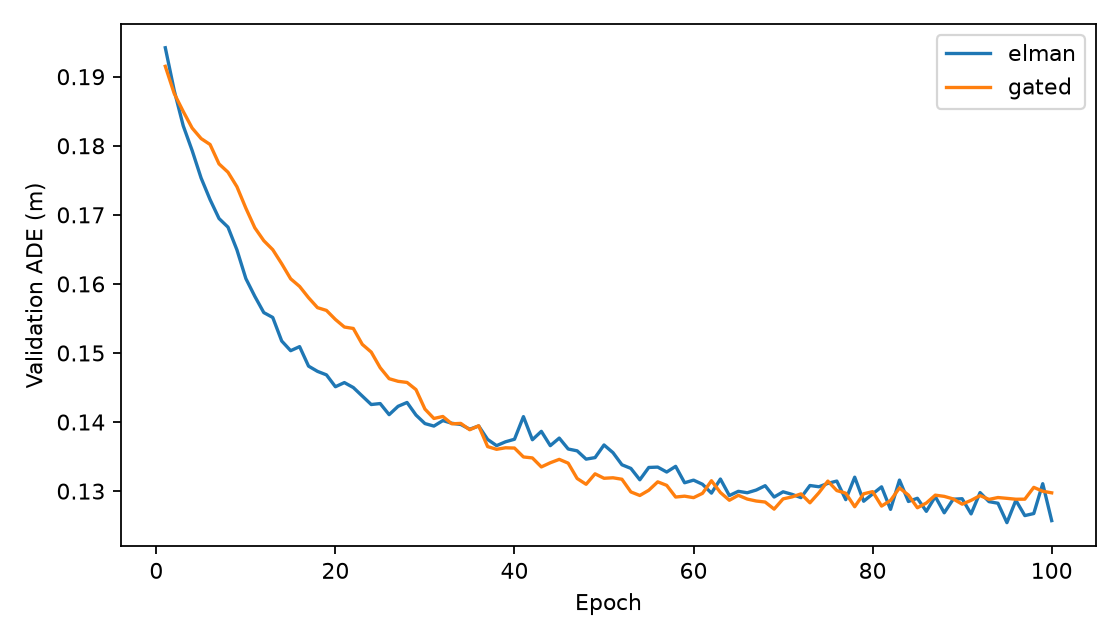

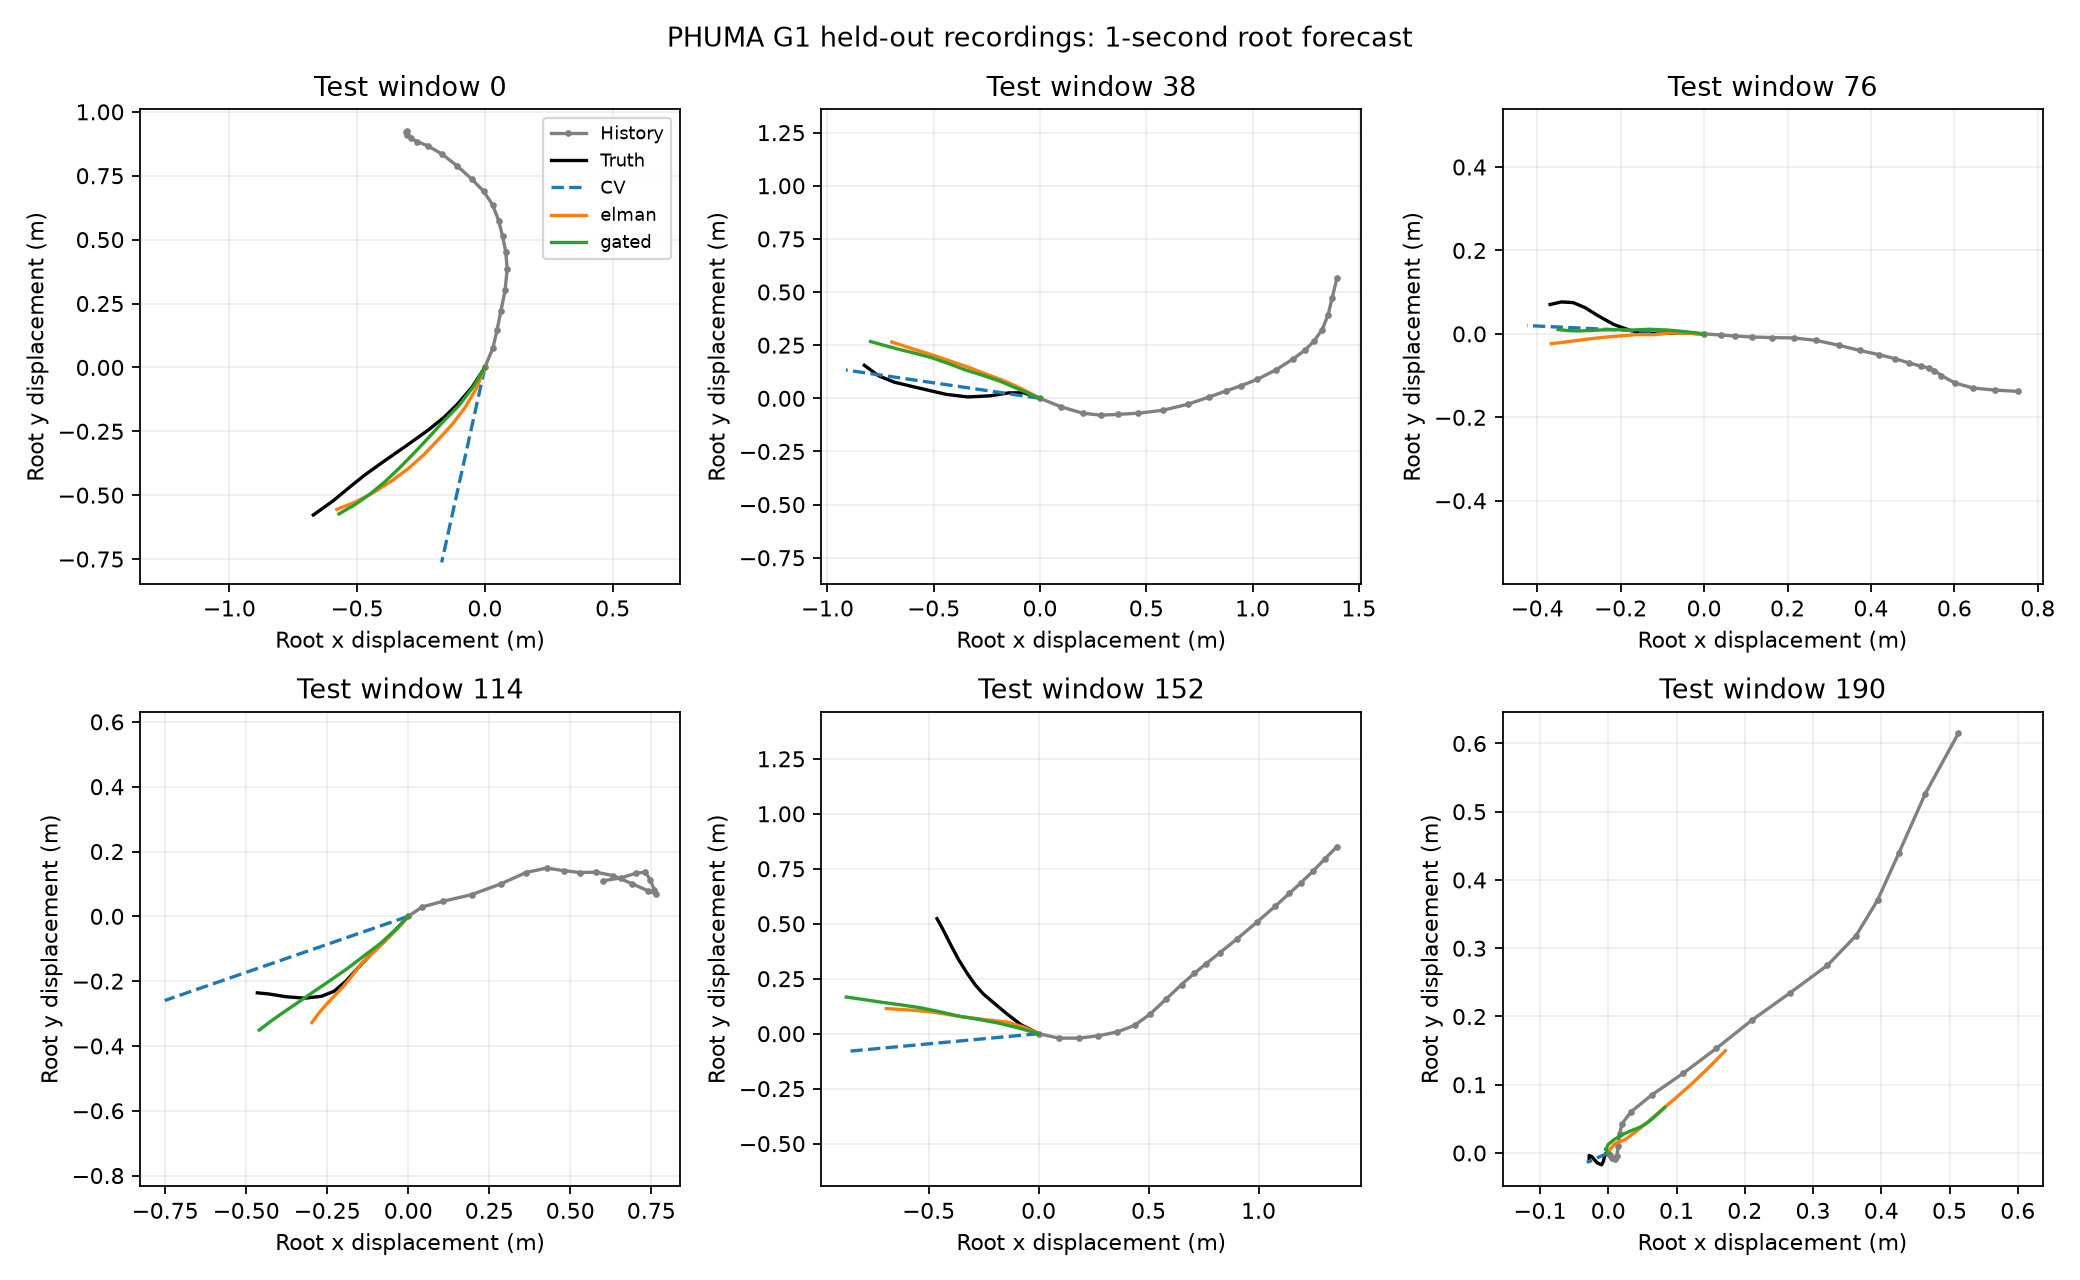

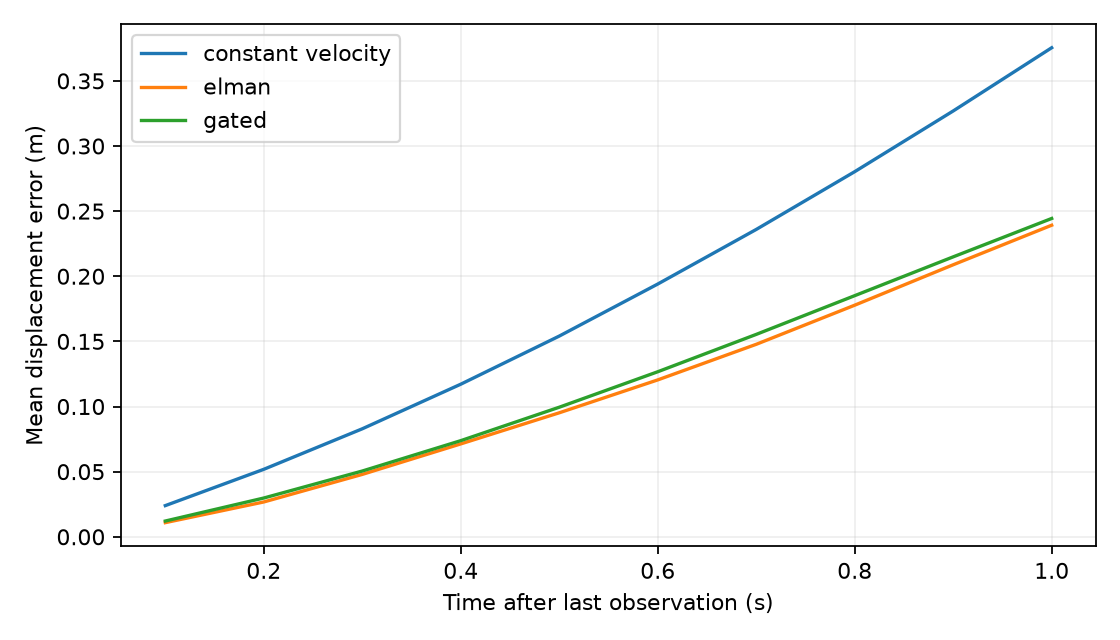

In [15]:
table = "| Model | Test ADE (m) | Test FDE (m) | Macro-source ADE (m) |\n"
table += "| --- | ---: | ---: | ---: |\n"
for name, metric in report["test"].items():
    macro = report["test_macro_source"][name]["ADE_m"]
    table += f"| {name} | {metric['ADE_m']:.4f} | {metric['FDE_m']:.4f} | {macro:.4f} |\n"
display(Markdown(table))
for name in report["models"]:
    gain = 100 * (1 - report["test"][name]["ADE_m"] / report["test"]["constant_velocity"]["ADE_m"])
    print(f"{name}: ADE reduction versus CV = {gain:.1f}%")
for filename in ("learning_curves.png", "trajectories.png", "error_by_horizon.png"):
    display(Image(filename=str(RUN / filename)))

## 6. Forecasting from one history and saving the result

Only the **20 historical points** of one test window are passed to the model. Adding back the last observed position gives an absolute forecast of shape `(10,2)`.
Select the model type by validation ADE, not test error. `forecast_history` can also accept your own historical positions in meters, sampled at 10 Hz in the same coordinate system.
The checkpoint is produced by training in this notebook and contains the training-set normalization statistics.

In [16]:
@torch.no_grad()
def forecast_history(history, checkpoint_path):
    saved = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    config = saved["config"]
    history = torch.as_tensor(history, dtype=torch.float32)
    if history.shape != (config["obs_len"], 2) or not torch.isfinite(history).all():
        raise ValueError(f"Expected finite ({config['obs_len']}, 2) history")
    model = {"elman": ElmanRNN, "gated": MyRNN}[saved["model"]](
        4, config["hidden"], 2 * config["pred_len"])
    model.load_state_dict(saved["state_dict"])
    model.eval()
    history = history[None]
    features = (make_features(history, saved["dt"]) - saved["mean"]) / saved["std"]
    baseline = constant_velocity(history, config["pred_len"], saved["dt"])
    relative = predict(model, features, baseline, saved["output_scale"])
    return (relative + history[:, -1:])[0].numpy()

selected_model = min(report["models"], key=lambda n: report["models"][n]["val_ADE_m"])
with np.load(RUN / "test_predictions.npz", allow_pickle=False) as saved_predictions:
    history = saved_predictions["observed"][0].copy()
    expected = saved_predictions[selected_model + "_relative"][0] + history[-1]
forecast = forecast_history(history, RUN / f"{selected_model}_best.pt")
np.testing.assert_allclose(forecast, expected, atol=1e-5, rtol=1e-5)
np.save(RUN / "example_history.npy", history)
np.save(RUN / "example_forecast.npy", forecast)
print("Selected by validation:", selected_model, "forecast shape:", forecast.shape)
print("Future absolute XY positions (meters):\n", forecast)
print("Outputs:", RUN)

Selected by validation: elman forecast shape: (10, 2)
Future absolute XY positions (meters):
 [[0.85838205 6.4634094 ]
 [0.81504464 6.3899193 ]
 [0.76514727 6.3240433 ]
 [0.71086645 6.2645187 ]
 [0.6535795  6.20447   ]
 [0.5910605  6.148593  ]
 [0.52404624 6.098647  ]
 [0.45418385 6.054504  ]
 [0.38292152 6.01729   ]
 [0.31164902 5.988759  ]]
Outputs: /private/var/folders/hg/cy46vq7d3wg86rr95t7_h2qh0000gn/T/humanoid-notebook-check-yx5d1c3w/instructor/humanoid_rnn_workspace/outputs/run_20261030_153435_849695


## H. Experiments and submission, 5 points

Submit the completed student notebook with its execution outputs and a short analysis. If using scripts, submit `student.py` and the experimental outputs. Include at least the model equations, training configuration, validation curves, ADE/FDE for the baselines and both RNNs, test trajectory plots, and one failure case with possible explanations.

Explain why source motions are grouped before splitting, why normalization uses only training data, why an RNN may outperform constant velocity, and why a more complex model may not perform better. Choose hyperparameters using the validation set. Do not repeatedly tune against test results after evaluating the test set. Failure cases may support interpretation, but must not be used to remove test data after observing errors.

A suggested classroom target for the fixed split is **ADE <= 0.15 m and FDE <= 0.30 m, with better performance than the constant-velocity baseline**. Allow reasonable variation across dependency versions and hardware. Grading should emphasize implementation correctness, sound experimental practice, and analysis rather than one specific decimal value. The reference results use robot reference motions and do not establish real-robot deployment accuracy.

After completing the Elman components, set `MODELS` to `"elman"` in the notebook for an intermediate experiment. Set it back to `"both"` after completing all tasks. After modifying a function definition, rerun its cell before rerunning the checks and training. The unfilled student's `NotImplementedError` identifies the TODO that needs to be completed.

### Your analysis

1. Why should source motions be split before windowing, instead of randomly splitting overlapping windows?
2. What information leakage is prevented by training-only normalization and by constructing velocities from history only?
3. Compare ADE/FDE for both RNNs and the constant-velocity baseline, and explain the differences.
4. Select a test case with a relatively large error and discuss the effects of stopping, turning, or motion intent.
5. Explain the data source and identify practical tasks to which these results cannot be directly transferred.

Write your analysis here.

### Instructor discussion notes

Reference run with seed=42: CV ADE/FDE=0.1842/0.3754 m; Elman=0.1146/0.2392 m; gated=0.1192/0.2444 m.
Use the actual outputs from your run. A more complex gated model need not perform better on a small dataset.
Discuss parameter counts, overfitting, and validation curves, but do not infer general architectural superiority from one run.
Historical velocity provides short-term trends, while the RNN learns deviations from constant velocity. Turning and stopping remain uncertain without motion intent.
Randomly splitting overlapping windows places highly similar segments in both training and test sets; grouping by source motion before splitting reduces this problem.
The reference motions have undergone upstream processing and do not include online sensor noise or a closed-loop controller. Their forecast errors do not directly measure real-robot navigation performance.